# 02 · Sensor simulator: what would our ESP32 node read?

We have no ESP32 data yet. So at every CPCB station we place **3 virtual sensor units** and ask:
*given the true air and weather of this hour, what would each sensor on our board report?*

All simulator code is in one file, **`simulator.py`** — a box:
```
X  (true hourly air + weather of one station, data/2_clean)  ──►  simulator.simulate(X, station, unit)  ──►  Y  (what that ESP32 would log)
```

| X (input) | goes into | Y (output) |
|---|---|---|
| true PM2.5, PM10 | SPS30, BH1750 | pm1, pm25, pm10 (raw), lux |
| true CO, NO2, O3 (+ VOC made from CO) | MQ-7, MQ-135, SGP41 | mq7_rs, mq135_rs (Ω), sraw_voc, sraw_nox (ticks) |
| true T, dew point, RH | HDC1080, SPS30 | t, rh |
| true pressure | BMP280 | p |
| true wind | anemometer | wind_speed, wind_u, wind_v |
| rain | rain board | rain_frac |
| sunshine | BH1750, HDC1080 | lux, (warmer t) |
| — | ESP32 hourly processing | pm25_corr, pm10_corr, coarse_ratio, dust, gas baselines, pm_state, aqi_pm |

- **Not machine learning:** every formula below is physics or a datasheet curve.
- Each unit draws its own errors **once** (bias, gain, drift) — like three real boards would differ.
- The true PM stays in Y only as **the answer** (`true_pm25`, `true_pm10`), never as a model input.
- **At real inference this box is not used**: the real sensors on the ESP32 produce Y.

This notebook explains the box sensor by sensor (formula → small demo on one real winter week), then runs it
for all stations. Notation: $U(a,b)$ = random value between a and b drawn **once per unit**;
$\mathcal{N}(0,\sigma)$ = random noise **every hour**. Sources: `docs/simulator_sources.md`.

In [1]:
# imports (simulator.py lives in the project folder)
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
import simulator as sim

In [2]:
# folders
DATA = Path("../data")
CLEAN = DATA / "2_clean"
OUT = DATA / "3_sensors"
OUT.mkdir(parents=True, exist_ok=True)
UNITS_PER_STATION = 3

In [3]:
# demo data: one station, one winter week (used to show each sensor below)
DEMO_STATION = "anand_vihar_delhi_dpcc"
X = pd.read_parquet(CLEAN / f"{DEMO_STATION}.parquet")
local = X.ts.dt.tz_convert("Asia/Kolkata")
own_typical = {g: X[g].groupby([local.dt.month, local.dt.hour]).median() for g in ("co_ppm", "no2_ppb", "o3_ppb")}
truth = sim.station_truth(X, own_typical, DEMO_STATION)
week = ((local >= "2023-12-01") & (local < "2023-12-08")).to_numpy()
w = truth[week].reset_index(drop=True)
w_time = local[week].to_numpy()
rng = sim.make_rng(DEMO_STATION, 0)
print(len(w), "hours in the demo week")

168 hours in the demo week


## 1. The true air that every unit at a station breathes  (`station_truth`)

**Aerosol water uptake κ** (how much particles swell in humid air) changes slowly over days:
$$\kappa_t = 0.30 + 0.10\,z_t,\qquad z_t = \phi\,z_{t-1} + \sqrt{1-\phi^2}\,\varepsilon_t,\quad \phi = e^{-1/48}$$
(mean 0.30; Delhi measurements 0.05-0.77; changes over ~48 h)

**VOC** (for the SGP41) is not measured by CPCB, so we tie it to traffic CO:
$$VOC_{ppb} = 20 + r \cdot CO_{ppb},\qquad r = U(0.03, 0.10)\ \text{per station}$$

**Gas gaps:** the gas sensors need a value every hour → short gaps (≤ 3 h) are interpolated, longer ones use the
usual value for that month and hour.

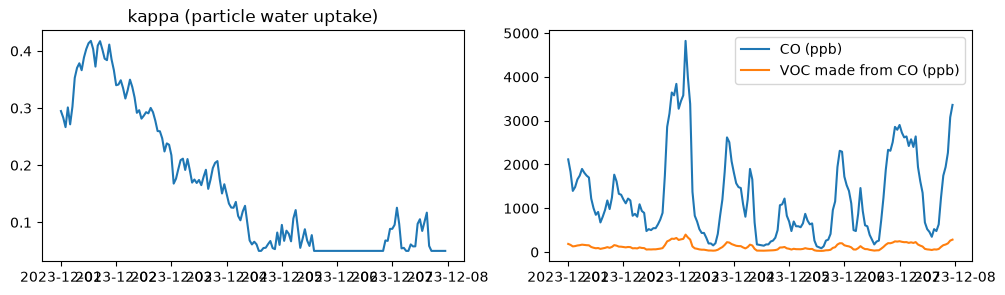

In [4]:
# demo: kappa over the week, and VOC made from CO
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(w_time, w.kappa)
ax[0].set_title("kappa (particle water uptake)")
ax[1].plot(w_time, w.co_ppm * 1000, label="CO (ppb)")
ax[1].plot(w_time, w.voc_ppb, label="VOC made from CO (ppb)")
ax[1].legend()
plt.show()

## 2. One formula per sensor

### 2.1 SPS30 — particulate matter  (`sps30_params`, `sps30`)
Three effects, calibrated so that the SPS30-vs-reference slope matches an IIT-Delhi field study (1.46-1.86):

1. **Humid particles look bigger** (κ-Köhler growth, Crilley 2018). The air inside the sensor is a bit warmer
   ($\Delta T$), which lowers the RH the particles see:
   $$C = 1 + \frac{\kappa/1.65}{1/a_w - 1},\qquad a_w = \min(RH_{inside}/100,\ 0.97)$$
2. **Dust is almost invisible** to the SPS30 (efficiency $e$); dust = part of the coarse mass:
   $$\text{dust}_{2.5} = \min(0.25\,(PM_{10}-PM_{2.5}),\ PM_{2.5}),\qquad \text{fine} = PM_{2.5} - \text{dust}_{2.5}$$
3. **It reads high** (scale $s$); PM10 is mostly guessed from small particles:
   $$PM_{2.5}^{sps} = s\,(\text{fine}\cdot C + e\cdot\text{dust}_{2.5}) + \mathcal{N}(0,\ 0.05x + 1)$$
   $$PM_{10}^{sps} = PM_{2.5}^{sps}(1+q) + s\,f\,(PM_{10}-PM_{2.5}),\qquad PM_{1}^{sps} = r\,s\,\text{fine}\cdot C$$

| parameter | value | source |
|---|---|---|
| $s$ | U(1.15, 1.55) | IIT-Delhi field study, SCAQMD |
| $\Delta T$ | U(1.5, 3.5) °C | needed to match field R² ≈ 0.9 |
| $e$ | U(0.20, 0.40) | Gautam 2025 (dust storm) |
| $q,\ f,\ r$ | U(0.02, 0.10), U(0.05, 0.25), U(0.75, 0.95) | Kuula 2020 |
| fog (RH > 95 %) | extra + U(0, 0.20) | spec |

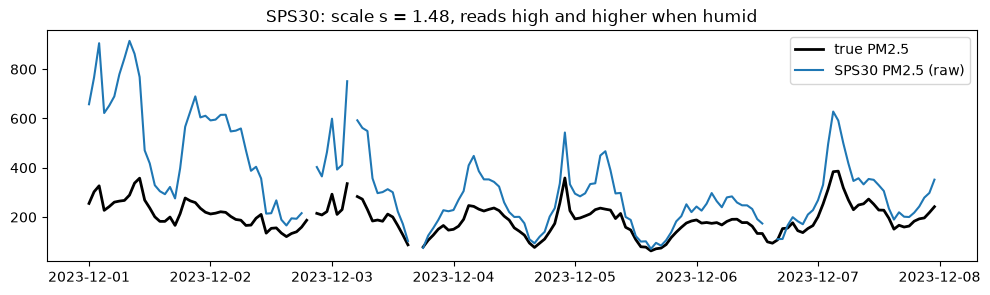

In [5]:
# demo: true PM2.5 vs what one SPS30 reports
p = sim.sps30_params(rng)
rh_inside = np.clip(sim.rh_from_dewpoint(w.td, w.t + p["dt_inside"]), 0, 100).to_numpy()
pm1, pm25, pm10 = sim.sps30(w.pm25.to_numpy(), w.pm10.to_numpy(), rh_inside, w.kappa.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, w.pm25, "k", lw=2, label="true PM2.5")
plt.plot(w_time, pm25, label="SPS30 PM2.5 (raw)")
plt.legend()
plt.title(f"SPS30: scale s = {p['scale']:.2f}, reads high and higher when humid")
plt.show()

### 2.2 HDC1080 — temperature and humidity  (`hdc1080_params`, `hdc1080`)
The sun heats the radiation shield, less when the wind cools it (Nakamura & Mahrt 2005):
$$T = T_{true} + b_T + c\,\frac{SW/1000}{1 + k\,ws} + \mathcal{N}(0, 0.3)$$
RH follows from the true dew point at the (warmer) sensor temperature, plus the datasheet error:
$$RH = RH(T_d, T) + b_{RH} + \mathcal{N}(0, 2)$$

| parameter | value | source |
|---|---|---|
| $b_T$ | U(-0.5, 0.5) °C | datasheet |
| $c$ | U(1.0, 2.5) °C per kW/m² | Nakamura & Mahrt |
| $b_{RH}$ | U(-2, 2) % | datasheet |

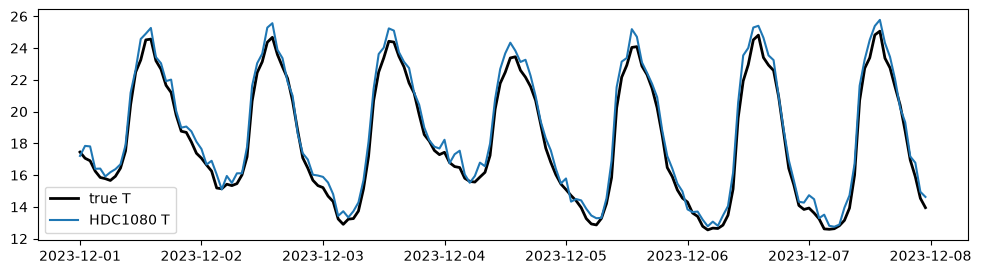

In [6]:
# demo: true vs sensor temperature (look at the daytime bumps from the sun)
p = sim.hdc1080_params(rng)
t, rh = sim.hdc1080(w.t.to_numpy(), w.td.to_numpy(), w.swrad.to_numpy(), 0.7 * w.ws.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, w.t, "k", lw=2, label="true T")
plt.plot(w_time, t, label="HDC1080 T")
plt.legend()
plt.show()

### 2.3 BMP280 — pressure  (`bmp280_params`, `bmp280`)
Pressure drops about 1 hPa per 8.3 m of height (the node sits on a roof):
$$P = P_{true} - \frac{h}{8.3} + b_P + \mathcal{N}(0, 0.1)$$

| $h$ | U(3, 25) m | $b_P$ | U(-1, 1) hPa (datasheet) |
|---|---|---|---|

In [7]:
# demo: the sensor pressure is the true pressure shifted by the roof height
p = sim.bmp280_params(rng)
pressure = sim.bmp280(w.p.to_numpy(), p, rng)
print(f"roof height {p['height']:.1f} m -> mean difference {np.mean(pressure - w.p):.2f} hPa")

roof height 12.5 m -> mean difference -2.08 hPa


### 2.4 Anemometer + wind vane  (`wind_params`, `anemometer`)
Roof-top buildings shelter the cups (factor $k$); cups stop below 0.3 m/s; the vane is mounted a bit off north:
$$ws = k\,ws_{true} + \mathcal{N}(0, 0.3)\ \ (0 \text{ if } < 0.3),\qquad wd = wd_{true} + \delta + \mathcal{N}(0, 15°)$$

| $k$ | U(0.4, 1.0) | $\delta$ | U(-15°, 15°) |
|---|---|---|---|

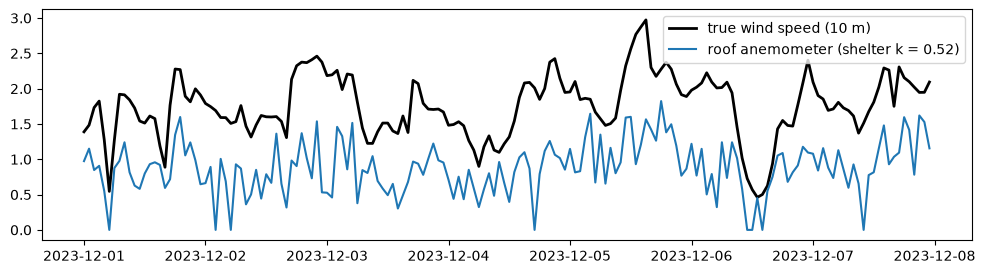

In [8]:
# demo: sheltered wind speed
p = sim.wind_params(rng)
ws, wd = sim.anemometer(w.ws.to_numpy(), w.wd.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, w.ws, "k", lw=2, label="true wind speed (10 m)")
plt.plot(w_time, ws, label=f"roof anemometer (shelter k = {p['shelter']:.2f})")
plt.legend()
plt.show()

### 2.5 Rain board  (`rain_params`, `rain_board`)
Wet (1) while it rains (> 0.1 mm/h), then dries linearly over $D$ hours; fog sometimes wets it
(2 % of hours with RH > 90 %):
$$\text{wet} = \begin{cases}1 & \text{raining}\\ \max(0,\ 1 - (h_{since}-1)/D) & \text{otherwise}\end{cases}$$

| $D$ | U(1, 2) h |
|---|---|

In [9]:
# demo: hours the board is wet in the week (December is dry: fog causes most wet hours)
p = sim.rain_params(rng)
wet = sim.rain_board(w.precip.to_numpy(), w.rh.to_numpy(), p, rng)
print(f"raining hours: {(w.precip > 0.1).sum()}, wet board hours: {(wet > 0).sum()}")

raining hours: 0, wet board hours: 0


### 2.6 BH1750 — light  (`bh1750_params`, `bh1750`)
Sunlight (W/m²) times the luminous efficacy (≈ 108 lm/W, Littlefair 1985), dimmed by smog:
$$lux = g \cdot 108 \cdot SW \cdot e^{-\beta\,PM_{2.5}/100} + \mathcal{N}(0, 50),\qquad 0 \text{ at night}$$

| $g$ (mounting/shade) | U(0.6, 1.2) | $\beta$ | U(0, 0.2) |
|---|---|---|---|

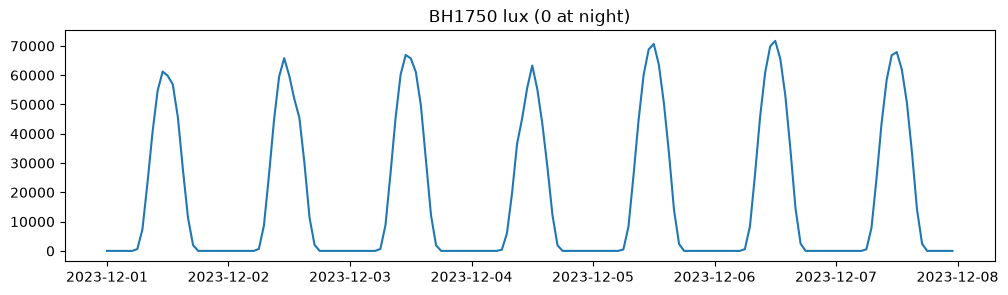

In [10]:
# demo: light follows the sun
p = sim.bh1750_params(rng)
lux = sim.bh1750(w.swrad.to_numpy(), w.pm25.to_numpy(), p, rng)
plt.figure(figsize=(12, 3))
plt.plot(w_time, lux)
plt.title("BH1750 lux (0 at night)")
plt.show()

### 2.7 MQ-7 (CO) and MQ-135 (air quality) — metal-oxide sensors  (`mq7`, `mq135`, `mos_resistance`)
Datasheet curves are straight lines on log-log paper, plus temperature/humidity effects and slow drift:
$$\ln R_s = \ln R_0 + b\,\ln(\text{gas} + c_0) + g_T (T-20) + g_{RH}(RH-65) + d\cdot\text{days} + \mathcal{N}(0, 0.05)$$
- MQ-7: gas = CO (ppm).
- MQ-135: gas = $w_{CO}\,CO + w_{VOC}\,VOC/1000$, and NO2 (oxidising) **raises** $R_s$: extra $+\,g_{ox}\ln(1 + NO_2/20)$.

| parameter | MQ-7 | MQ-135 | source |
|---|---|---|---|
| $R_0$ | lognormal, median 20 kΩ | median 30 kΩ | datasheets |
| slope $b$ | U(-0.70, -0.45) | U(-0.55, -0.40) | datasheet Fig. 3 |
| background $c_0$ (H2) | U(0.3, 1.0) ppm | U(0.3, 1.0) ppm | Novelli 1999 |
| $g_T$, $g_{RH}$ | U(-0.016, -0.007), U(-0.008, -0.003) | same | datasheet Fig. 4 |
| drift $d$ per day | U(-0.001, 0.001) | same | spec |

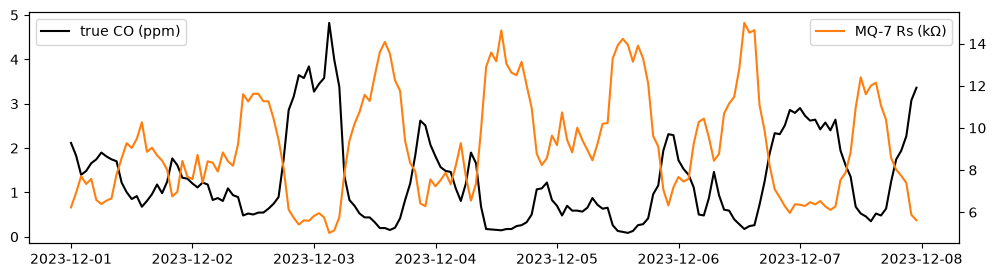

In [11]:
# demo: MQ-7 resistance falls when CO rises
p = sim.mq7_params(rng)
rs = sim.mq7(w.co_ppm.to_numpy(), w.t.to_numpy(), w.rh.to_numpy(), np.zeros(len(w)), p, rng)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(w_time, w.co_ppm, "k", label="true CO (ppm)")
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(w_time, rs / 1000, color="tab:orange", label="MQ-7 Rs (kΩ)")
ax2.legend(loc="upper right")
plt.show()

### 2.8 SGP41 — VOC and NOx raw "ticks"  (`sgp41_params`, `sgp41`)
The raw signal is proportional to log(resistance) (Sensirion datasheet): VOC ticks **fall** when VOC rises,
NOx ticks **rise** with oxidising gases (NO2 and ozone):
$$VOC_{ticks} = B_V - k_V\ln(1 + VOC/100) + k_{ox}\ln(1 + (NO_2+O_3)/50) + \text{drift} + \mathcal{N}(0, 50)$$
$$NOx_{ticks} = B_N + k_N\ln\!\left(1 + \frac{NO_2 + w\,O_3}{10}\right) + \text{drift} + \mathcal{N}(0, 30)$$

| parameter | value | source |
|---|---|---|
| $B_V$, $B_N$ | U(25000, 35000), U(14000, 17000) | spec / datasheet example |
| $k_V$ | U(1040, 1507) | datasheet: -710…-1030 ticks per doubling |
| $k_N$ | U(1437, 3039) | datasheet: +950…+2010 ticks per doubling |
| $k_{ox}$, $w$ | U(0, 700), U(2, 5) | datasheet Fig. 2-3 |
| drift | U(-5, 5) ticks/day | TODO_VERIFY |

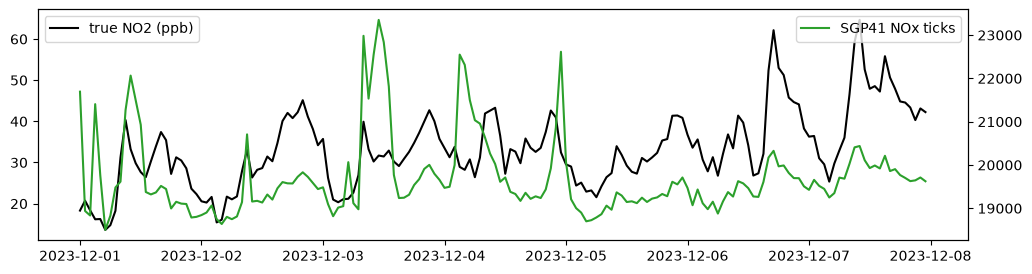

In [12]:
# demo: NOx ticks follow NO2
p = sim.sgp41_params(rng)
voc, nox = sim.sgp41(w.voc_ppb.to_numpy(), w.no2_ppb.to_numpy(), w.o3_ppb.to_numpy(), np.zeros(len(w)), p, rng)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(w_time, w.no2_ppb, "k", label="true NO2 (ppb)")
ax.legend(loc="upper left")
ax2 = ax.twinx()
ax2.plot(w_time, nox, color="tab:green", label="SGP41 NOx ticks")
ax2.legend(loc="upper right")
plt.show()

### 2.9 Sensor faults  (`sps30_faults`)
Each hour has a 1 % chance of a missing PM reading, and about once a year the SPS30 is down for U(6, 48) hours.
(Hours where CPCB itself has no PM are simply missing — that is not a sensor fault.)

In [13]:
# demo: faults over one simulated year
missing, outage = sim.sps30_faults(8766, rng)
print(f"random missing hours: {missing.sum()}, outage hours: {outage.sum()}")

random missing hours: 110, outage hours: 0


## 3. What the ESP32 does every hour  (`process_on_device`)

| step | formula |
|---|---|
| humidity correction of PM | $PM_{corr} = PM_{sps} / C(RH, \kappa = 0.4)$ (fixed κ until we calibrate on site) |
| coarse ratio | $(PM_{10}-PM_{2.5}) / \max(PM_1, 1)$ |
| dust flag | coarse ratio > 0.5 and RH < 60 % |
| gas baselines | clean-air level = 90 % quantile of the last 7 days (NOx: 10 %) |
| PM state | ok / filled (1 h hole) / Model B fallback (≤ 24 h) / unavailable |
| CPCB AQI | from 24-h means, needs ≥ 16 measured hours |

**CPCB AQI** (India): each pollutant's 24-h mean is mapped linearly inside its band, AQI = the larger sub-index.

| AQI band | 0-50 | 51-100 | 101-200 | 201-300 | 301-400 | 401-500 |
|---|---|---|---|---|---|---|
| PM2.5 (µg/m³) | 0-30 | 31-60 | 61-90 | 91-120 | 121-250 | 250+ |
| PM10 (µg/m³) | 0-50 | 51-100 | 101-250 | 251-350 | 351-430 | 430+ |

$$I = I_{lo} + \frac{I_{hi} - I_{lo}}{B_{hi} - B_{lo}}(C - B_{lo})$$

Breakpoints checked against the official CPCB NAQI table (`docs/cpcb_aqi_breakpoints.png`). Our two choices: a band
starts where the previous one ended (so 30.5 µg/m³ is not "between" bands), and the open "Severe" band runs to
380 (PM2.5) / 510 (PM10) as in CPCB's AQI calculator; anything above is AQI 500.

In [14]:
# demo: a few AQI values
for pm in (25, 45, 75, 180, 300):
    print(f"PM2.5 24-h mean {pm:4d} ug/m3 -> sub-index {sim.sub_index(pm, sim.PM25_LIMITS):.0f}")

PM2.5 24-h mean   25 ug/m3 -> sub-index 42
PM2.5 24-h mean   45 ug/m3 -> sub-index 76
PM2.5 24-h mean   75 ug/m3 -> sub-index 150
PM2.5 24-h mean  180 ug/m3 -> sub-index 347
PM2.5 24-h mean  300 ug/m3 -> sub-index 439


## 4. The whole box on the demo station: X → Y  (`simulate`)

In [15]:
# run the box for unit 0 of the demo station and look at a few hours of Y
Y = sim.simulate(X, DEMO_STATION, unit=0, network_typical=own_typical)
Y[week].head()

,ts,pm1,pm25,pm10,t,rh,p,wind_speed,wind_u,wind_v,...,coarse_ratio,dust,Rbase7,Rbase135,base_voc,base_nox,aqi_pm,sim_outage,true_pm25,true_pm10
51840,2023-11-30 18:30:00+00:00,511.412079,709.578610,747.932391,17.076616,98.429360,992.545640,1.388977,-0.269940,-1.362494,...,0.074996,False,1430.322719,113503.304162,27035.3,18575.5,343.0,False,255.25,439.75
51841,2023-11-30 19:30:00+00:00,642.497061,839.748021,882.161892,16.394696,100.000000,992.495351,1.055655,-0.387033,-0.982147,...,0.066014,False,1430.322719,113503.304162,27035.3,18575.5,343.0,False,302.50,482.25
51842,2023-11-30 20:30:00+00:00,669.466407,899.418400,943.417990,16.400882,100.000000,992.261739,1.116909,-0.500051,-0.998716,...,0.065723,False,1430.322719,113503.304162,27035.3,18575.5,343.0,False,326.75,500.75
51843,2023-11-30 21:30:00+00:00,534.657029,632.907968,665.011613,16.559820,95.743721,992.187591,1.640589,-0.519539,-1.556152,...,0.060045,False,1430.322719,113503.304162,27035.3,18575.5,341.0,False,227.25,364.50
51844,2023-11-30 22:30:00+00:00,497.427689,601.161680,633.438701,15.513625,98.556164,992.020464,0.712138,-0.111655,-0.703331,...,0.064888,False,1430.322719,113503.304162,27035.3,18575.5,340.0,False,242.50,396.00


## 5. Run it for every station

In [16]:
# load the clean tables; keep stations with at least one year (8760 h) of BOTH PM2.5 and PM10
# (the SPS30 formula and the targets need both; Sector 16A Faridabad has no PM10)
clean = {p.stem: pd.read_parquet(p) for p in sorted(CLEAN.glob("*.parquet"))}
stations = [s for s, df in clean.items() if (df.pm25.notna() & df.pm10.notna()).sum() >= 8760]
print(len(stations), "stations; dropped:", sorted(set(clean) - set(stations)))

32 stations; dropped: ['sector_16a_faridabad_hspcb']


In [17]:
# typical gas level per (month, IST hour) over all stations: fallback for stations without a gas
all_clean = pd.concat(clean[s] for s in stations)
local_all = all_clean.ts.dt.tz_convert("Asia/Kolkata")
network_typical = {g: all_clean[g].groupby([local_all.dt.month, local_all.dt.hour]).median() for g in ("co_ppm", "no2_ppb", "o3_ppb")}
del all_clean

In [18]:
# simulate 3 units per station and save them (skips files that already exist)
unit_table = []
for station in stations:
    for unit in range(UNITS_PER_STATION):
        path = OUT / f"{station}_u{unit}.parquet"
        if not path.exists():
            sim.simulate(clean[station], station, unit, network_typical).to_parquet(path, index=False)
        params = sim.draw_unit(sim.make_rng(station, unit))           # this unit's errors (same every run)
        unit_table.append({"station": station, "unit": unit,
                           **{f"{s}.{k}": round(v, 4) for s, d in params.items() for k, v in d.items()}})
pd.DataFrame(unit_table).to_csv(OUT / "units.csv", index=False)
print(len(unit_table), "virtual units")

96 virtual units


## 6. Is it realistic?
**SPS30 vs reference in Delhi winter.** IIT-Delhi field study (Kumar et al. 2025): slope 1.46-1.86, R² ≈ 0.91.
We undo the device correction and fit raw SPS30 PM2.5 against true PM2.5 for every unit.

In [19]:
# slope and R2 of raw SPS30 vs true PM2.5 in winter, per unit
def winter_fit(rec):
    winter = rec.ts.dt.tz_convert("Asia/Kolkata").dt.month.isin([11, 12, 1, 2])
    raw = rec.pm25_corr * (1 + (0.4 / 1.65) / (1 / np.clip(rec.rh / 100, 1e-9, 0.95) - 1))
    ok = winter & rec.pm_state.eq("ok") & raw.notna() & rec.true_pm25.notna()
    slope = np.polyfit(rec.true_pm25[ok], raw[ok], 1)[0]
    r2 = np.corrcoef(rec.true_pm25[ok], raw[ok])[0, 1] ** 2
    return slope, r2


fits = pd.DataFrame([winter_fit(pd.read_parquet(p)) for p in sorted(OUT.glob("*_u*.parquet"))], columns=["slope", "r2"])
fits.describe().round(2)

,slope,r2
count,96.00,96.00
mean,1.77,0.86
std,0.15,0.03
min,1.50,0.78
25%,1.66,0.84
50%,1.75,0.86
75%,1.88,0.89
max,2.09,0.93


In [20]:
# check: the median slope must be inside the field range
print(f"median slope {fits.slope.median():.2f}, median R2 {fits.r2.median():.2f}, "
      f"units inside 1.46-1.86: {fits.slope.between(1.46, 1.86).mean():.0%}")
assert 1.46 <= fits.slope.median() <= 1.86

median slope 1.75, median R2 0.86, units inside 1.46-1.86: 71%


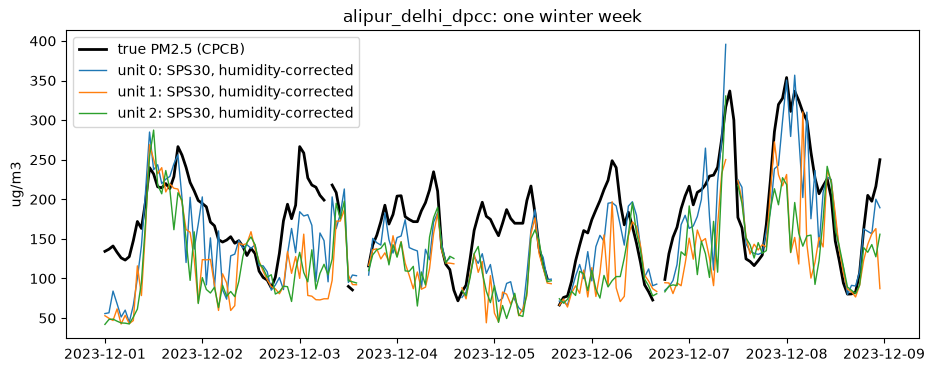

In [21]:
# one winter week: true PM2.5 vs what the 3 units of one station report
station = stations[0]
plt.figure(figsize=(11, 4))
for unit in range(3):
    rec = pd.read_parquet(OUT / f"{station}_u{unit}.parquet").set_index("ts").tz_convert("Asia/Kolkata").loc["2023-12-01":"2023-12-08"]
    if unit == 0:
        plt.plot(rec.index, rec.true_pm25, "k", lw=2, label="true PM2.5 (CPCB)")
    plt.plot(rec.index, rec.pm25_corr, lw=1, label=f"unit {unit}: SPS30, humidity-corrected")
plt.title(f"{station}: one winter week")
plt.ylabel("ug/m3")
plt.legend()
plt.show()

In [22]:
# do the gas sensors follow their gas? (correlation with the true value at one station)
rec = pd.read_parquet(OUT / f"{station}_u0.parquet").merge(clean[station][["ts", "co_ppm", "no2_ppb", "o3_ppb", "swrad"]], on="ts")
checks = {"MQ-7 ln(Rs/Rbase) vs ln CO": (np.log(rec.mq7_rs / rec.Rbase7), np.log(rec.co_ppm.clip(lower=0.05))),
          "SGP41 NOx vs NO2+O3": (rec.sraw_nox - rec.base_nox, np.log1p((rec.no2_ppb + 3.5 * rec.o3_ppb) / 10)),
          "BH1750 vs sunshine": (np.log1p(rec.lux), rec.swrad)}
for name, (a, b) in checks.items():
    both = pd.DataFrame({"a": a, "b": b}).replace([np.inf, -np.inf], np.nan).dropna()
    print(f"{name:30s} r = {both.a.corr(both.b):+.2f}")

MQ-7 ln(Rs/Rbase) vs ln CO     r = -0.74
SGP41 NOx vs NO2+O3            r = +0.88
BH1750 vs sunshine             r = +0.79
